# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 4: Custom CNN Model Development Using PyTorch

**Goals**
- Build a custom Convolutional Neural Network (CNN) from scratch
- Implement convolutional, pooling and fully connected layers
- Experiment with activation and loss functions
- Train the model using a PyTorch `Dataset` and `DataLoader`
- Experiment with different batch sizes and learning rates

> Builds on Step 2 (preprocessing and augmentation choices) and Step 3 (neural network fundamentals: layers, activations, loss, backpropagation, gradient descent). Uses the dataset cached in Step 1 (`zacharielegault/Kermany2017-OCT`).
>
> **Runtime note:** this notebook trains many small models. `QUICK_MODE = True` (section 4.1, the default) shrinks the images to 64 x 64 and the experiments to a few minutes on a CPU. Set it to `False` for the larger, slower run (best on a GPU).

In [1]:
# Run once if the packages are missing
%pip install -q torch torchvision datasets pillow matplotlib seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

In [3]:
import copy
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import v2
from datasets import load_dataset

SEED = 42
if os.path.exists("preprocessing_config.json"):            # written at the end of Step 2
    with open("preprocessing_config.json") as f:
        SEED = json.load(f).get("seed", SEED)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
rng = np.random.default_rng(SEED)
sns.set_style("whitegrid")

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.15.0+cpu | device: cpu


## 4.1 Data: a PyTorch `Dataset` and `DataLoader`
Decoding full-size OCT scans from disk every epoch is slow. So we **resize each scan once, keep it as an 8-bit tensor in memory**, and apply augmentation and normalization on the fly inside a custom `Dataset`.

Choices (consistent with Step 2):
- **Grey-level, 1 channel.** A from-scratch CNN has no need for the 3 repeated channels that pretrained RGB models want.
- **Resize to a square.** Step 2 used 224 x 224; here it is **64 x 64** in quick mode and 128 x 128 otherwise, to keep CPU training practical.
- **Augmentation on training data only:** horizontal flip, small rotation/shift/zoom, mild brightness/contrast. No vertical flip.
- A random sample of the training split is used, **keeping the natural class imbalance**, so class weights and loss functions in 4.5 have something to fix. The test split is untouched.

In [4]:
QUICK_MODE = True          # True: finishes in a few minutes on a CPU. False: bigger, slower, more accurate.

if QUICK_MODE:
    IMG_SIZE, TRAIN_SAMPLE = 64, 4000        # image side in pixels; scans drawn from the training split (None = all)
    EXP_TRAIN_SIZE, EXP_EPOCHS = 1200, 4     # size and length of each screening experiment in 4.4-4.6
    FINAL_EPOCHS = 10                        # epochs for the final model in 4.7
    BS_LIST, LR_LIST, RUN_GRID = [32, 64, 128], [1e-4, 1e-3, 1e-2], False
else:                                        # Step 2 used 224; use IMG_SIZE = 224 only on a GPU
    IMG_SIZE, TRAIN_SAMPLE = 128, 8000
    EXP_TRAIN_SIZE, EXP_EPOCHS = 3000, 5
    FINAL_EPOCHS = 15
    BS_LIST, LR_LIST, RUN_GRID = [16, 32, 64, 128], [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], True
VAL_FRACTION = 0.15

dataset = load_dataset("zacharielegault/Kermany2017-OCT")
train_data, test_data = dataset["train"], dataset["test"]
class_names = train_data.features["label"].names
n_classes = len(class_names)
train_labels_all = np.array(train_data["label"])
test_labels_all = np.array(test_data["label"])
print("Classes:", class_names)
print("Full training split:", {class_names[k]: int(v) for k, v in zip(*np.unique(train_labels_all, return_counts=True))})

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Full training split: {'CNV': 37205, 'DME': 11348, 'DRUSEN': 8616, 'NORMAL': 51140}


In [5]:
def cache_images(ds, idx, size):
    arr = np.empty((len(idx), size, size), dtype=np.uint8)
    for k, i in enumerate(idx):
        arr[k] = np.asarray(ds[int(i)]["image"].convert("L").resize((size, size), Image.BILINEAR))
    return arr

n_train = len(train_data) if TRAIN_SAMPLE is None else min(TRAIN_SAMPLE, len(train_data))
cache_file = f"oct_cache_{IMG_SIZE}_{n_train}_{SEED}.npz"

if os.path.exists(cache_file):
    z = np.load(cache_file)
    X_pool, y_pool, X_test, y_test = z["X_pool"], z["y_pool"], z["X_test"], z["y_test"]
    print("Loaded cache", cache_file)
else:
    t0 = time.time()
    pool_idx = rng.choice(len(train_data), n_train, replace=False)
    X_pool, y_pool = cache_images(train_data, pool_idx, IMG_SIZE), train_labels_all[pool_idx]
    X_test, y_test = cache_images(test_data, np.arange(len(test_data)), IMG_SIZE), test_labels_all
    np.savez_compressed(cache_file, X_pool=X_pool, y_pool=y_pool, X_test=X_test, y_test=y_test)
    print(f"Resized and cached {len(X_pool) + len(X_test):,} scans in {time.time() - t0:.0f}s -> {cache_file}")

# stratified train / validation split
val_idx = []
for c in range(n_classes):
    ids = rng.permutation(np.where(y_pool == c)[0])
    val_idx.append(ids[: int(len(ids) * VAL_FRACTION)])
val_idx = np.concatenate(val_idx)
is_val = np.zeros(len(y_pool), dtype=bool); is_val[val_idx] = True
X_train, y_train = X_pool[~is_val], y_pool[~is_val]
X_val, y_val = X_pool[is_val], y_pool[is_val]

counts = np.bincount(y_train, minlength=n_classes)
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")
print("Train class counts:", dict(zip(class_names, counts.tolist())))
print("Test class counts: ", dict(zip(class_names, np.bincount(y_test, minlength=n_classes).tolist())))

Resized and cached 5,000 scans in 54s -> oct_cache_64_4000_42.npz
train (3402, 64, 64) | val (598, 64, 64) | test (1000, 64, 64)
Train class counts: {'CNV': 1172, 'DME': 357, 'DRUSEN': 286, 'NORMAL': 1587}
Test class counts:  {'CNV': 250, 'DME': 250, 'DRUSEN': 250, 'NORMAL': 250}


In [6]:
# Normalization from TRAIN pixels only (single channel)
PIX_MEAN = float(X_train.mean() / 255.0)
PIX_STD = float(X_train.std() / 255.0)
print(f"mean {PIX_MEAN:.4f}, std {PIX_STD:.4f}")

# class weights: rarer class -> larger weight (used by the weighted loss in 4.5)
class_weights = torch.tensor(counts.sum() / (n_classes * counts), dtype=torch.float32)
print("Class weights:", dict(zip(class_names, class_weights.numpy().round(2).tolist())))

mean 0.1904, std 0.2081
Class weights: {'CNV': 0.7300000190734863, 'DME': 2.380000114440918, 'DRUSEN': 2.9700000286102295, 'NORMAL': 0.5400000214576721}


In [7]:
class OCTDataset(Dataset):
    """In-memory OCT dataset. Images are uint8 tensors (1, H, W); transforms run on the fly."""

    def __init__(self, images, labels, transform=None):
        self.x = torch.from_numpy(images).unsqueeze(1)          # N x 1 x H x W, uint8
        self.y = torch.from_numpy(labels).long()
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.x[i]
        if self.transform is not None:
            x = self.transform(x)                                # augmentation on uint8
        x = (x.float() / 255.0 - PIX_MEAN) / PIX_STD             # to float, normalize
        return x, self.y[i]

train_tf = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
])

train_ds = OCTDataset(X_train, y_train, transform=train_tf)
val_ds = OCTDataset(X_val, y_val)
test_ds = OCTDataset(X_test, y_test)
print(f"train {len(train_ds):,} | val {len(val_ds):,} | test {len(test_ds):,}")

x0, y0 = train_ds[0]
print("One sample:", tuple(x0.shape), x0.dtype, "| label:", class_names[int(y0)], f"| value range {x0.min():.2f} to {x0.max():.2f}")

train 3,402 | val 598 | test 1,000
One sample: (1, 64, 64) torch.float32 | label: DRUSEN | value range -0.73 to 3.89


Batch: (16, 1, 64, 64) torch.float32 | labels (16,) torch.int64


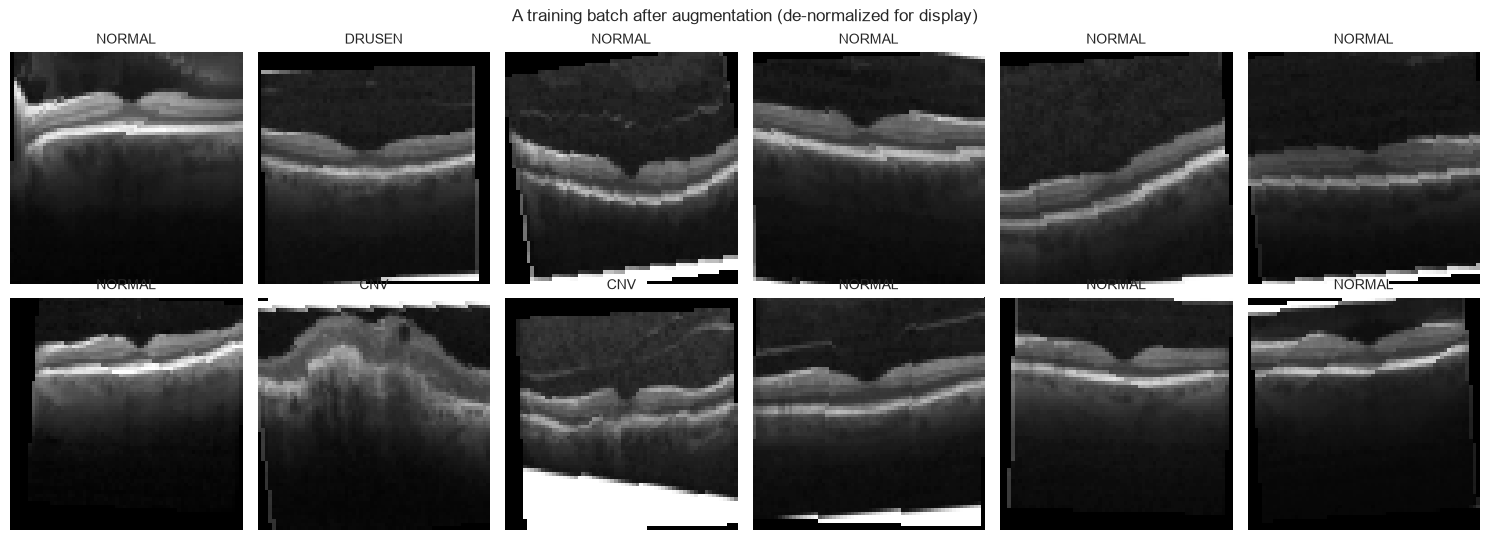

In [8]:
def make_loader(ds, batch_size, shuffle, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    # num_workers=0 avoids multiprocessing problems on Windows / Jupyter
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0, generator=g,
                      pin_memory=(device.type == "cuda"))

val_loader = make_loader(val_ds, 128, False)
test_loader = make_loader(test_ds, 128, False)

# fixed random subset of the training set for the quick experiments
exp_idx = rng.choice(len(train_ds), min(EXP_TRAIN_SIZE, len(train_ds)), replace=False)
exp_ds = Subset(train_ds, exp_idx.tolist())

xb, yb = next(iter(make_loader(train_ds, 16, True)))
print("Batch:", tuple(xb.shape), xb.dtype, "| labels", tuple(yb.shape), yb.dtype)

mean_, std_ = PIX_MEAN, PIX_STD
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, img_t, lab in zip(axes.ravel(), xb[:12], yb[:12]):
    ax.imshow((img_t[0] * std_ + mean_).clamp(0, 1).numpy(), cmap="gray")
    ax.set_title(class_names[int(lab)], fontsize=10); ax.axis("off")
plt.suptitle("A training batch after augmentation (de-normalized for display)")
plt.tight_layout(); plt.show()

## 4.2 Build the custom CNN
A CNN replaces the plain fully connected layers of Step 3 with layers that look at **small neighbourhoods** and reuse the same filter at every position. That is what lets it detect a fluid pocket or a drusen bump wherever it appears.

| Layer | What it does | Key setting |
|---|---|---|
| `Conv2d` | slides small learned filters over the image, producing feature maps | 3 x 3 kernels, `padding=1` keeps size |
| `BatchNorm2d` | normalizes each channel, making training stabler and faster | after each conv |
| Activation | adds non-linearity | ReLU by default (compared in 4.4) |
| `MaxPool2d(2)` | keeps the strongest response in each 2 x 2 block, halving height and width | gives some shift tolerance |
| Global average pool | turns each final feature map into one number | removes the huge flatten layer |
| `Linear` + `Dropout` | fully connected classifier head | dropout fights overfitting |

Architecture: 4 blocks of **Conv - BatchNorm - Activation - Pool** with 16, 32, 64, 128 channels, then global average pooling and a two-layer classifier.

In [9]:
def make_activation(name):
    return {"relu": nn.ReLU(), "leaky_relu": nn.LeakyReLU(0.1), "gelu": nn.GELU(), "tanh": nn.Tanh()}[name]

class OCTCNN(nn.Module):
    def __init__(self, n_classes=4, in_channels=1, channels=(16, 32, 64, 128),
                 act="relu", pool="max", fc_units=128, dropout=0.4):
        super().__init__()
        layers, c_in = [], in_channels
        for c_out in channels:
            layers += [
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                make_activation(act),
                nn.MaxPool2d(2) if pool == "max" else nn.AvgPool2d(2),
            ]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)                     # global average pooling
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c_in, fc_units),
            make_activation(act),
            nn.Dropout(dropout),
            nn.Linear(fc_units, n_classes),                    # raw scores (logits); softmax lives in the loss
        )
        self._init_weights(act)

    def _init_weights(self, act):
        nonlin = "relu" if act in ("relu", "gelu") else "leaky_relu" if act == "leaky_relu" else "tanh"
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                if nonlin == "tanh":
                    nn.init.xavier_uniform_(m.weight)
                else:
                    nn.init.kaiming_normal_(m.weight, nonlinearity=nonlin)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

def make_model(**kw):
    set_seed()                      # same starting weights for every experiment
    return OCTCNN(n_classes=n_classes, **kw).to(device)

model = make_model()
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTrainable parameters: {n_params:,}")

OCTCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13): Batch

### Trace the shapes through the network
Each pool halves the height and width while the number of channels grows, so the network trades spatial detail for richer features.

In [10]:
model.eval()
x = torch.zeros(1, 1, IMG_SIZE, IMG_SIZE, device=device)
rows = [("input", tuple(x.shape))]
with torch.no_grad():
    for layer in model.features:
        x = layer(x)
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.AvgPool2d)):
            rows.append((layer.__class__.__name__, tuple(x.shape)))
    x = model.gap(x); rows.append(("GlobalAvgPool", tuple(x.shape)))
    x = model.classifier(x); rows.append(("Classifier -> logits", tuple(x.shape)))
display(pd.DataFrame(rows, columns=["layer", "output shape (N, C, H, W)"]))

,layer,"output shape (N, C, H, W)"
0,input,"(1, 1, 64, 64)"
1,Conv2d,"(1, 16, 64, 64)"
2,MaxPool2d,"(1, 16, 32, 32)"
3,Conv2d,"(1, 32, 32, 32)"
4,MaxPool2d,"(1, 32, 16, 16)"
5,Conv2d,"(1, 64, 16, 16)"
6,MaxPool2d,"(1, 64, 8, 8)"
7,Conv2d,"(1, 128, 8, 8)"
8,MaxPool2d,"(1, 128, 4, 4)"
9,GlobalAvgPool,"(1, 128, 1, 1)"


### What the convolutions see
Feature maps from the **untrained** network on one scan: each block turns the image into a stack of smaller, more abstract maps. After training (4.7) we look at them again.

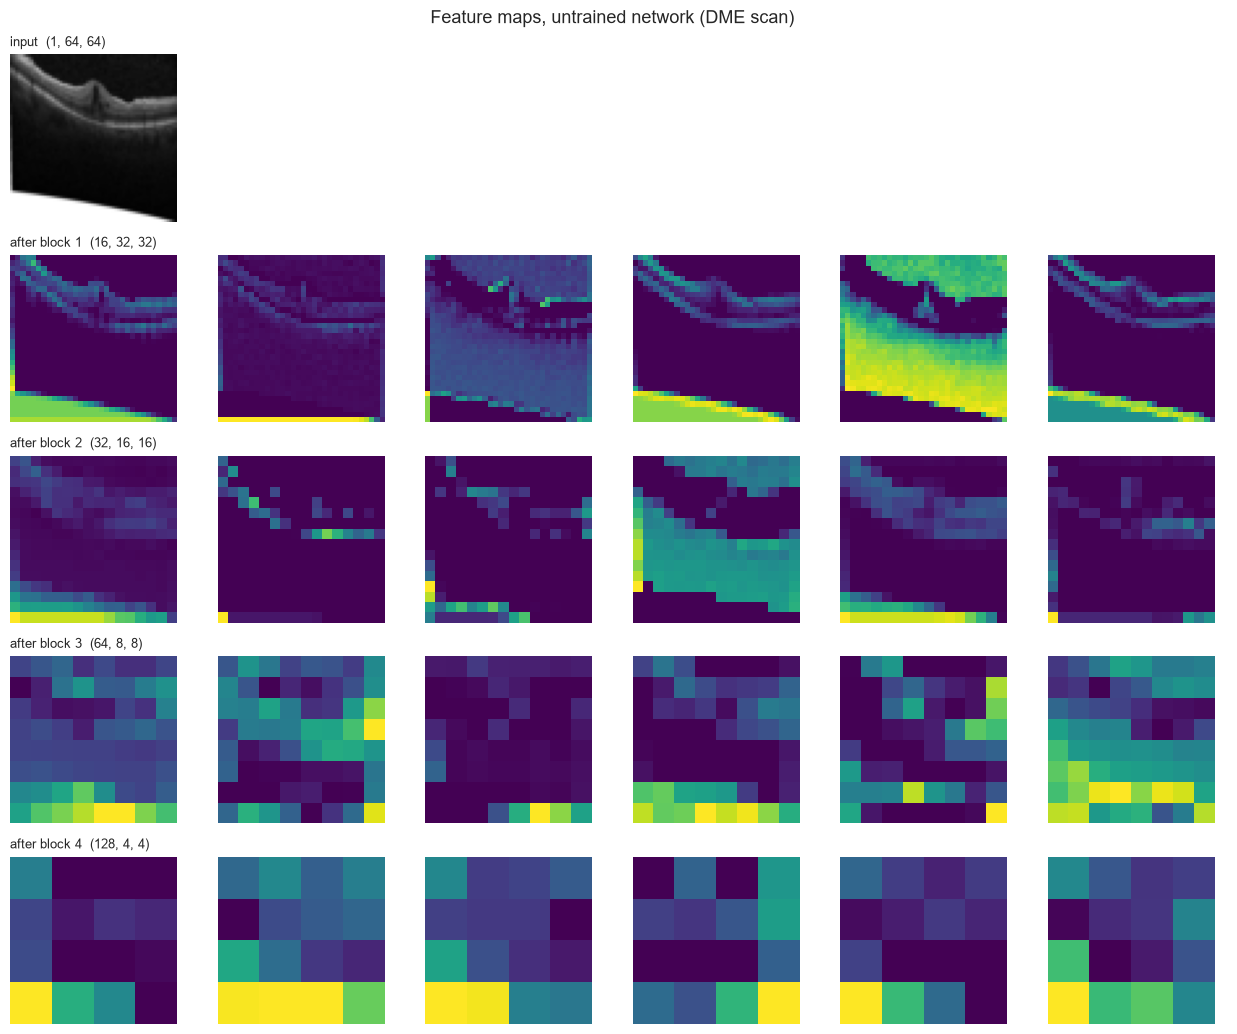

In [11]:
def show_feature_maps(model, img_t, title, n_maps=6):
    model.eval()
    x = img_t.unsqueeze(0).to(device)
    stages = [("input", x)]
    with torch.no_grad():
        for layer in model.features:
            x = layer(x)
            if isinstance(layer, (nn.MaxPool2d, nn.AvgPool2d)):
                stages.append((f"after block {len(stages)}", x))
    fig, axes = plt.subplots(len(stages), n_maps, figsize=(2.1 * n_maps, 2.1 * len(stages)))
    for r, (name, t) in enumerate(stages):
        for c in range(n_maps):
            ax = axes[r, c]; ax.axis("off")
            if c < t.shape[1]:
                ax.imshow(t[0, c].cpu().numpy(), cmap="viridis" if r else "gray")
        axes[r, 0].set_title(f"{name}  {tuple(t.shape[1:])}", fontsize=9, loc="left")
    plt.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()

sample_i = int(np.where(y_val == class_names.index("DME"))[0][0])
sample_img, sample_label = val_ds[sample_i]
show_feature_maps(model, sample_img, "Feature maps, untrained network (DME scan)")

## 4.3 Training and evaluation tools
We write them once and reuse them for every experiment:
- **Loss functions** (4.5): plain cross-entropy, class-weighted cross-entropy, label smoothing and focal loss.
- **`fit`**: mini-batch training with AdamW, optional cosine learning-rate schedule, and the weights from the best validation epoch restored at the end.
- **Metrics**: accuracy and **macro F1** (the average F1 across classes). Macro F1 matters because the classes are imbalanced, and accuracy can hide poor results on the small classes.

Validation loss is always reported as plain cross-entropy so it stays comparable between experiments, even when training uses a different loss.

In [12]:
class FocalLoss(nn.Module):
    """Cross-entropy that down-weights easy examples: (1 - p_t)^gamma * CE."""
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma, self.weight = gamma, weight
    def forward(self, logits, y):
        logp = F.log_softmax(logits, dim=1)
        ce = F.nll_loss(logp, y, weight=self.weight, reduction="none")
        pt = torch.exp(-F.nll_loss(logp, y, reduction="none"))
        return ((1 - pt) ** self.gamma * ce).mean()

def make_loss(name):
    w = class_weights.to(device)
    return {
        "ce":              nn.CrossEntropyLoss(),
        "weighted_ce":     nn.CrossEntropyLoss(weight=w),
        "label_smoothing": nn.CrossEntropyLoss(label_smoothing=0.1),
        "focal":           FocalLoss(gamma=2.0, weight=w),
    }[name]

def confusion(y_true, y_pred):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def macro_f1(cm):
    tp = np.diag(cm).astype(float)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return float(f1.mean())

EVAL_LOSS = nn.CrossEntropyLoss()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys, loss_sum = [], [], 0.0
    for x, y in loader:
        out = model(x.to(device))
        loss_sum += EVAL_LOSS(out, y.to(device)).item() * len(y)
        probs.append(out.softmax(1).cpu()); ys.append(y)
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    pred = probs.argmax(1)
    cm = confusion(ys, pred)
    return {"loss": loss_sum / len(ys), "acc": float((pred == ys).mean()), "f1": macro_f1(cm),
            "cm": cm, "pred": pred, "true": ys, "probs": probs}

In [13]:
def fit(model, train_loader, val_loader, criterion, epochs, lr=1e-3, weight_decay=1e-4,
        cosine=False, patience=None, verbose=False):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if cosine else None
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "lr"]}
    best_f1, best_state, wait, t0 = -1.0, None, 0, time.time()

    for ep in range(epochs):
        model.train()
        loss_sum, correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            seen += len(y)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if sched: sched.step()

        v = predict(model, val_loader)
        for k, val in zip(["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"],
                          [loss_sum / seen, correct / seen, v["loss"], v["acc"], v["f1"]]):
            hist[k].append(val)
        if verbose:
            print(f"epoch {ep + 1:3d} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.3f} "
                  f"| val loss {v['loss']:.4f} acc {v['acc']:.3f} F1 {v['f1']:.3f}")
        if not np.isfinite(loss_sum):
            print("  (training diverged: loss is not finite)")
            break
        if v["f1"] > best_f1 + 1e-4:
            best_f1, best_state, wait = v["f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if patience and wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)                 # keep the best validation epoch
    hist["best_epoch"] = int(np.argmax(hist["val_f1"])) + 1
    hist["time"] = time.time() - t0
    return hist

### Smoke test: one short training run
A first run with the defaults (ReLU, cross-entropy, batch 32, learning rate 1e-3) on the quick-experiment subset, printed epoch by epoch. If this does not beat the 25% chance level, stop and debug before running the experiments.

In [14]:
base_loader = make_loader(exp_ds, 32, True)
m = make_model()
h = fit(m, base_loader, val_loader, make_loss("ce"), epochs=EXP_EPOCHS, lr=1e-3, verbose=True)
print(f"\nbest epoch {h['best_epoch']} | {h['time']:.0f}s total | chance level for 4 classes = 25%")

epoch   1 | train loss 1.2574 acc 0.525 | val loss 1.0399 acc 0.584 F1 0.301
epoch   2 | train loss 1.0038 acc 0.632 | val loss 1.1149 acc 0.559 F1 0.278
epoch   3 | train loss 0.9364 acc 0.672 | val loss 1.1607 acc 0.587 F1 0.324
epoch   4 | train loss 0.9036 acc 0.685 | val loss 0.8394 acc 0.706 F1 0.389

best epoch 4 | 126s total | chance level for 4 classes = 25%


## 4.4 Experiment: activation functions
Same architecture, data, loss, optimizer and seed; only the activation changes. **Tanh** saturates and tends to learn more slowly in deep stacks; **LeakyReLU** keeps a small gradient for negative inputs; **GELU** is a smooth ReLU-like function.

Each experiment uses `EXP_TRAIN_SIZE` training scans for `EXP_EPOCHS` epochs, so it is a *screening* test rather than a final result.

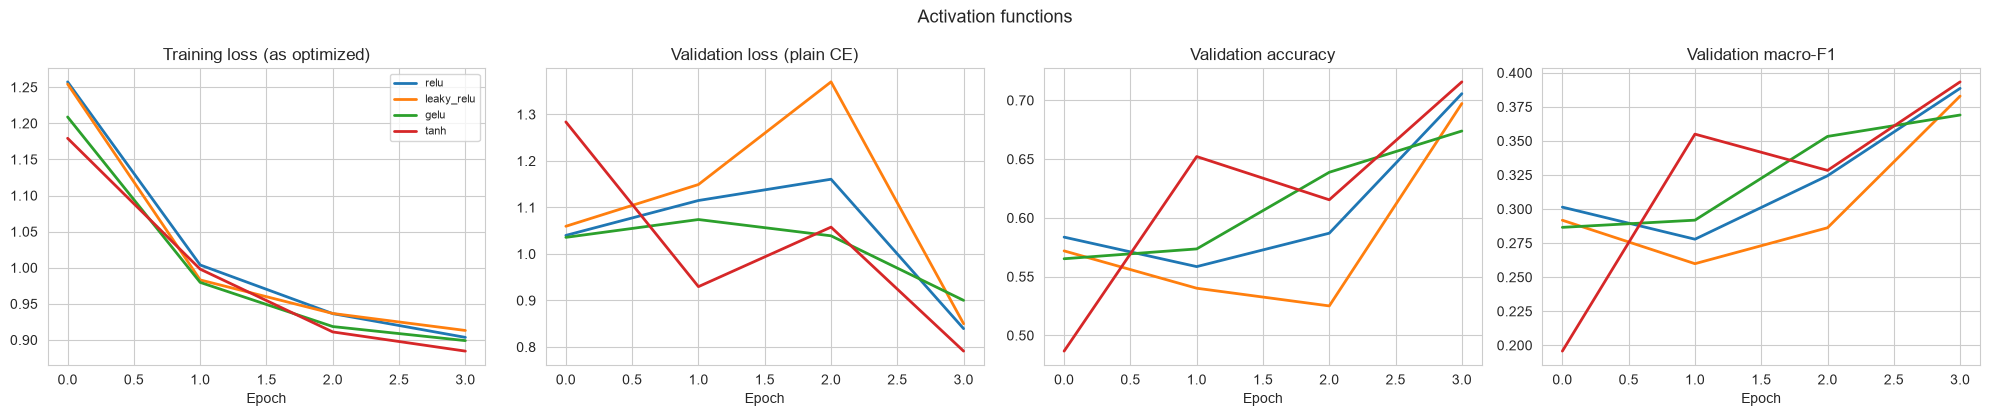

,activation,best val macro-F1,val acc,val loss (CE),best epoch,seconds
0,relu,0.3886,0.7057,0.8394,4,118.7122
1,leaky_relu,0.3829,0.6973,0.8500,4,112.1932
2,gelu,0.3690,0.6739,0.9002,4,110.0883
3,tanh,0.3933,0.7157,0.7911,4,120.8623


In [15]:
_run_cache = {}
def run(act="relu", loss="ce", bs=32, lr=1e-3, pool="max", epochs=EXP_EPOCHS):
    key = (act, loss, bs, lr, pool, epochs)
    if key not in _run_cache:                       # identical settings are trained only once
        model = make_model(act=act, pool=pool)
        loader = make_loader(exp_ds, bs, True)
        _run_cache[key] = fit(model, loader, val_loader, make_loss(loss), epochs=epochs, lr=lr)
    return _run_cache[key]

def summarize(results, key_name):
    rows = []
    for k, h in results.items():
        b = h["best_epoch"] - 1
        rows.append({key_name: k, "best val macro-F1": h["val_f1"][b], "val acc": h["val_acc"][b],
                     "val loss (CE)": h["val_loss"][b], "best epoch": h["best_epoch"], "seconds": h["time"]})
    return pd.DataFrame(rows).round(4)

def plot_results(results, title, label=lambda k: str(k)):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    for k, h in results.items():
        axes[0].plot(h["train_loss"], lw=2, label=label(k))
        axes[1].plot(h["val_loss"], lw=2, label=label(k))
        axes[2].plot(h["val_acc"], lw=2, label=label(k))
        axes[3].plot(h["val_f1"], lw=2, label=label(k))
    for ax, t in zip(axes, ["Training loss (as optimized)", "Validation loss (plain CE)", "Validation accuracy", "Validation macro-F1"]):
        ax.set_title(t); ax.set_xlabel("Epoch")
    axes[0].legend(fontsize=8)
    plt.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()

act_results = {a: run(act=a) for a in ["relu", "leaky_relu", "gelu", "tanh"]}
plot_results(act_results, "Activation functions")
display(summarize(act_results, "activation"))

**What to look for:** compare validation macro-F1 and how fast it rises. Differences of a point or two are within noise on a small validation set and a single seed, so only trust clear gaps.

### Pooling layer: max vs average
Max pooling keeps the strongest response (good for "is a feature present here?"); average pooling keeps the mean response (smoother, but can dilute small bright or dark features).

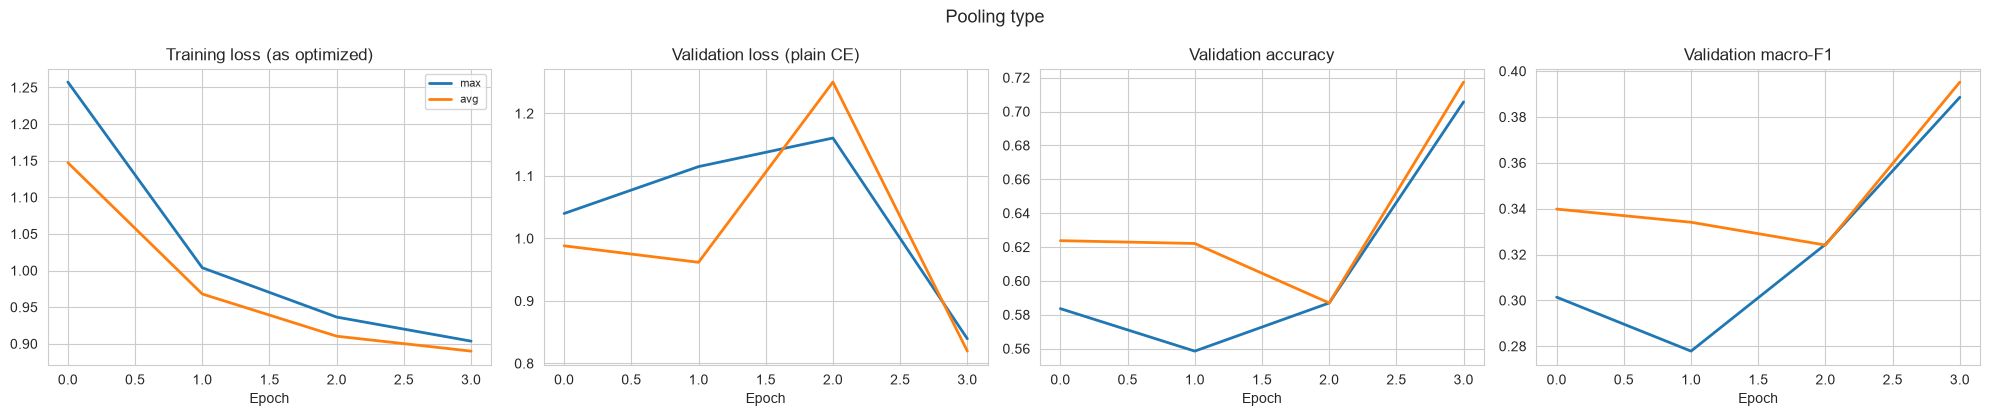

,pooling,best val macro-F1,val acc,val loss (CE),best epoch,seconds
0,max,0.3886,0.7057,0.8394,4,118.7122
1,avg,0.3952,0.7174,0.8197,4,120.6671


In [16]:
pool_results = {p: run(pool=p) for p in ["max", "avg"]}
plot_results(pool_results, "Pooling type")
display(summarize(pool_results, "pooling"))

## 4.5 Experiment: loss functions
The training set is imbalanced (see the counts in 4.1), so plain cross-entropy favours the common classes.

| Loss | Idea |
|---|---|
| `ce` | standard cross-entropy |
| `weighted_ce` | each class's loss is scaled by `N / (K * n_class)`, so mistakes on rare classes cost more |
| `label_smoothing` | softens the targets (0.9 / 0.033 instead of 1 / 0), reducing over-confidence |
| `focal` | multiplies by `(1 - p_t)^2`, so easy examples count less and hard ones more |

The training-loss curve is not comparable between losses (different formulas). Compare **validation macro-F1**, which is what we care about.

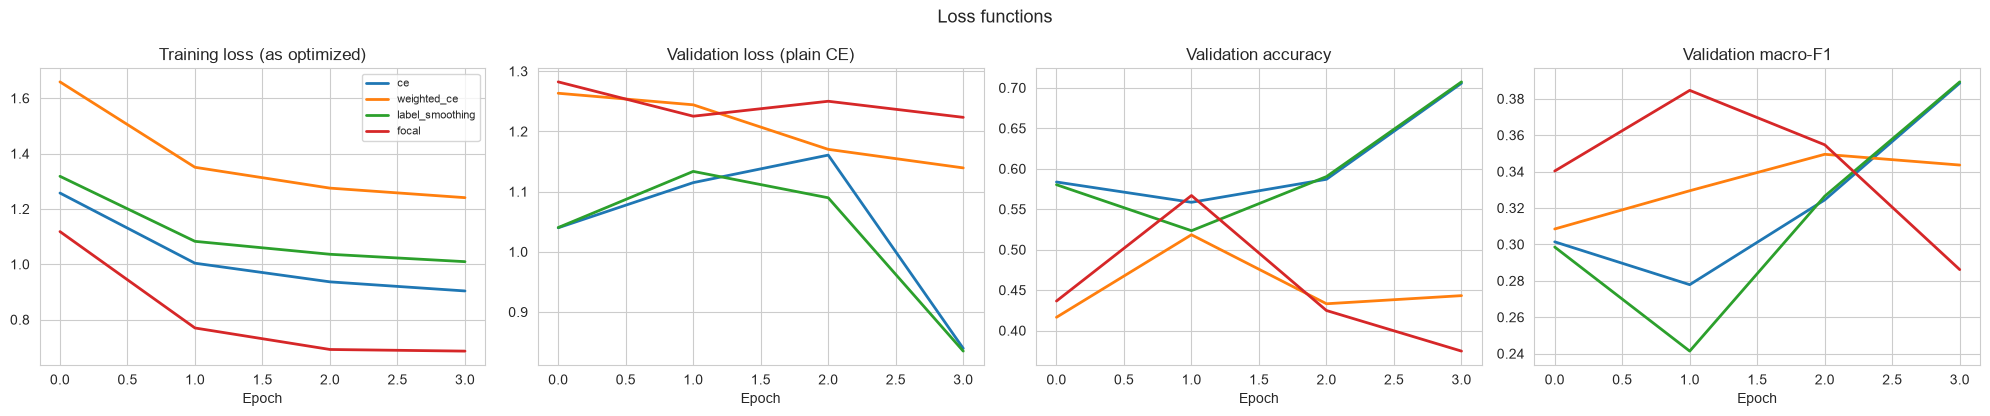

,loss,best val macro-F1,val acc,val loss (CE),best epoch,seconds
0,ce,0.3886,0.7057,0.8394,4,118.7122
1,weighted_ce,0.3495,0.4331,1.1702,3,112.4002
2,label_smoothing,0.3893,0.7074,0.8350,4,122.4897
3,focal,0.3846,0.5669,1.2253,2,108.7578


In [22]:
loss_results = {l: run(loss=l) for l in ["ce", "weighted_ce", "label_smoothing", "focal"]}
plot_results(loss_results, "Loss functions")
display(summarize(loss_results, "loss"))

**What to look for:** a loss that raises macro-F1 but not accuracy usually helps the rare classes (DRUSEN, DME) at the expense of the common ones. Check the per-class results of the final model in 4.7.

## 4.6 Experiment: batch size and learning rate
- **Batch size:** small batches give noisy gradients and many updates; large batches give smooth gradients, fewer updates and faster epochs.
- **Learning rate:** too small learns slowly; too large bounces or diverges. Batch size and learning rate interact, because larger batches tolerate (and often need) larger rates.

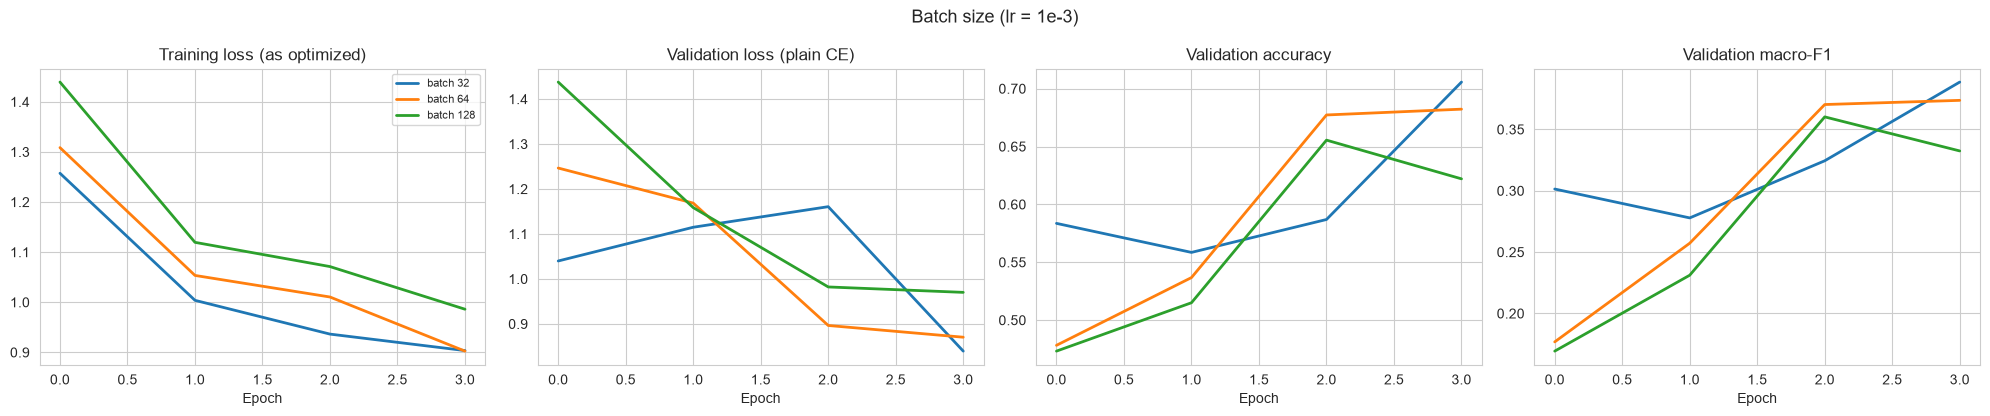

,batch size,best val macro-F1,val acc,val loss (CE),best epoch,seconds
0,32,0.3886,0.7057,0.8394,4,118.7122
1,64,0.3737,0.6823,0.8704,4,112.4625
2,128,0.3602,0.6555,0.9821,3,91.5765


In [17]:
bs_results = {bs: run(bs=bs) for bs in BS_LIST}
plot_results(bs_results, "Batch size (lr = 1e-3)", label=lambda k: f"batch {k}")
display(summarize(bs_results, "batch size"))

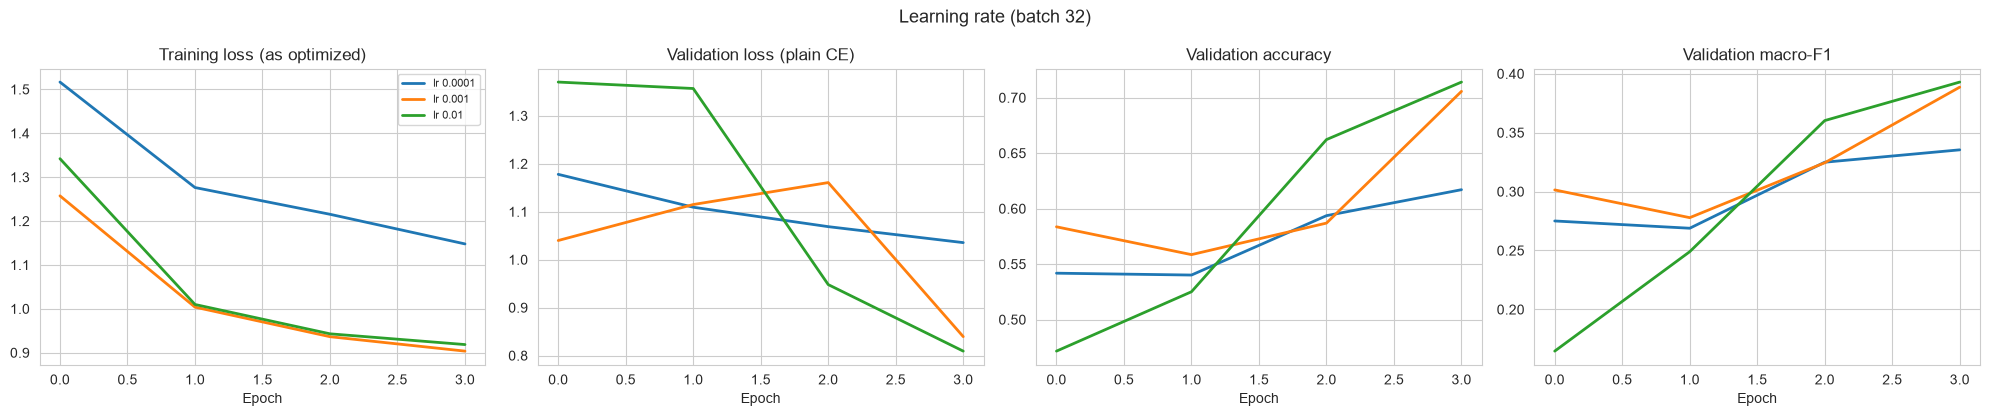

,learning rate,best val macro-F1,val acc,val loss (CE),best epoch,seconds
0,0.0001,0.3354,0.6171,1.0355,4,111.4237
1,0.0010,0.3886,0.7057,0.8394,4,118.7122
2,0.0100,0.3929,0.7140,0.8092,4,108.7470


In [20]:
lr_results = {lr: run(lr=lr) for lr in LR_LIST}
plot_results(lr_results, "Learning rate (batch 32)", label=lambda k: f"lr {k:g}")
display(summarize(lr_results, "learning rate"))

In [19]:
# Batch size x learning rate grid (validation macro-F1). Slow, so only with QUICK_MODE = False.
if RUN_GRID:
    grid_bs, grid_lr = [16, 64], [3e-4, 1e-3, 3e-3]
    grid = pd.DataFrame(index=[f"batch {b}" for b in grid_bs], columns=[f"lr {l:g}" for l in grid_lr], dtype=float)
    for b in grid_bs:
        for l in grid_lr:
            grid.loc[f"batch {b}", f"lr {l:g}"] = max(run(bs=b, lr=l)["val_f1"])
    plt.figure(figsize=(6, 3.2))
    sns.heatmap(grid, annot=True, fmt=".3f", cmap="viridis")
    plt.title("Best validation macro-F1: batch size x learning rate")
    plt.tight_layout(); plt.show()
else:
    print("Skipped in QUICK_MODE (set QUICK_MODE = False in section 4.1 to run the batch size x learning rate grid).")

Skipped in QUICK_MODE (set QUICK_MODE = False in section 4.1 to run the batch size x learning rate grid).


**What to look for:** a ridge of good settings rather than a single magic number; the largest learning rate may fail or turn unstable, and small batches may prefer smaller rates.

## 4.7 Final model
We combine the best setting from each experiment (highest validation macro-F1), train on the **full** training split for `FINAL_EPOCHS` epochs with a cosine learning-rate schedule and early stopping, and evaluate **once** on the untouched test split.

> The settings were chosen from single short runs on a small validation set, so treat them as a sensible starting point and override the dictionary below if you disagree.

In [23]:
def best_key(results):
    return max(results, key=lambda k: max(results[k]["val_f1"]))

FINAL = dict(act=best_key(act_results), pool=best_key(pool_results), loss=best_key(loss_results),
             bs=best_key(bs_results), lr=best_key(lr_results))
# FINAL = dict(act="relu", pool="max", loss="weighted_ce", bs=32, lr=1e-3)    # <- uncomment to override
print("Final configuration:", FINAL)

final_model = make_model(act=FINAL["act"], pool=FINAL["pool"])
final_loader = make_loader(train_ds, FINAL["bs"], True)
final_hist = fit(final_model, final_loader, val_loader, make_loss(FINAL["loss"]),
                 epochs=FINAL_EPOCHS, lr=FINAL["lr"], cosine=True, patience=5, verbose=True)
print(f"\nbest epoch {final_hist['best_epoch']} | {final_hist['time'] / 60:.1f} min")

Final configuration: {'act': 'tanh', 'pool': 'avg', 'loss': 'label_smoothing', 'bs': 32, 'lr': 0.01}
epoch   1 | train loss 1.2565 acc 0.473 | val loss 1.1565 acc 0.487 F1 0.193
epoch   2 | train loss 1.1943 acc 0.506 | val loss 1.1533 acc 0.532 F1 0.290
epoch   3 | train loss 1.1323 acc 0.590 | val loss 2.1055 acc 0.368 F1 0.168
epoch   4 | train loss 1.0707 acc 0.634 | val loss 0.8233 acc 0.722 F1 0.422
epoch   5 | train loss 0.9737 acc 0.687 | val loss 1.0272 acc 0.634 F1 0.377
epoch   6 | train loss 0.9169 acc 0.722 | val loss 1.1726 acc 0.564 F1 0.298
epoch   7 | train loss 0.8758 acc 0.740 | val loss 0.8756 acc 0.696 F1 0.418
epoch   8 | train loss 0.8362 acc 0.758 | val loss 0.7044 acc 0.758 F1 0.481
epoch   9 | train loss 0.8221 acc 0.770 | val loss 0.6754 acc 0.783 F1 0.529
epoch  10 | train loss 0.8110 acc 0.774 | val loss 0.6185 acc 0.783 F1 0.515

best epoch 9 | 12.4 min


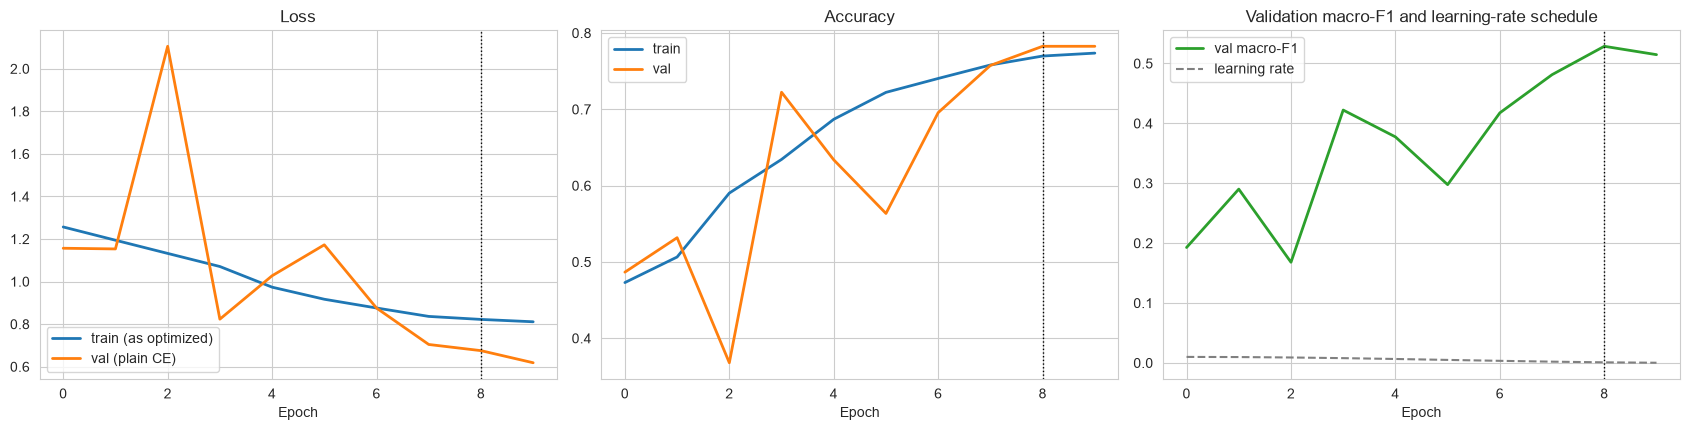

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(final_hist["train_loss"], lw=2, label="train (as optimized)")
axes[0].plot(final_hist["val_loss"], lw=2, label="val (plain CE)")
axes[0].set_title("Loss")
axes[1].plot(final_hist["train_acc"], lw=2, label="train")
axes[1].plot(final_hist["val_acc"], lw=2, label="val")
axes[1].set_title("Accuracy")
axes[2].plot(final_hist["val_f1"], lw=2, label="val macro-F1", color="tab:green")
axes[2].plot(final_hist["lr"], lw=1.5, ls="--", color="gray", label="learning rate")
axes[2].set_title("Validation macro-F1 and learning-rate schedule")
for ax in axes:
    ax.axvline(final_hist["best_epoch"] - 1, color="k", ls=":", lw=1)
    ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

Validation: acc 0.783 | macro-F1 0.529
Test:       acc 0.597 | macro-F1 0.512 | CE loss 0.982
(chance level for 4 balanced classes = 0.25)


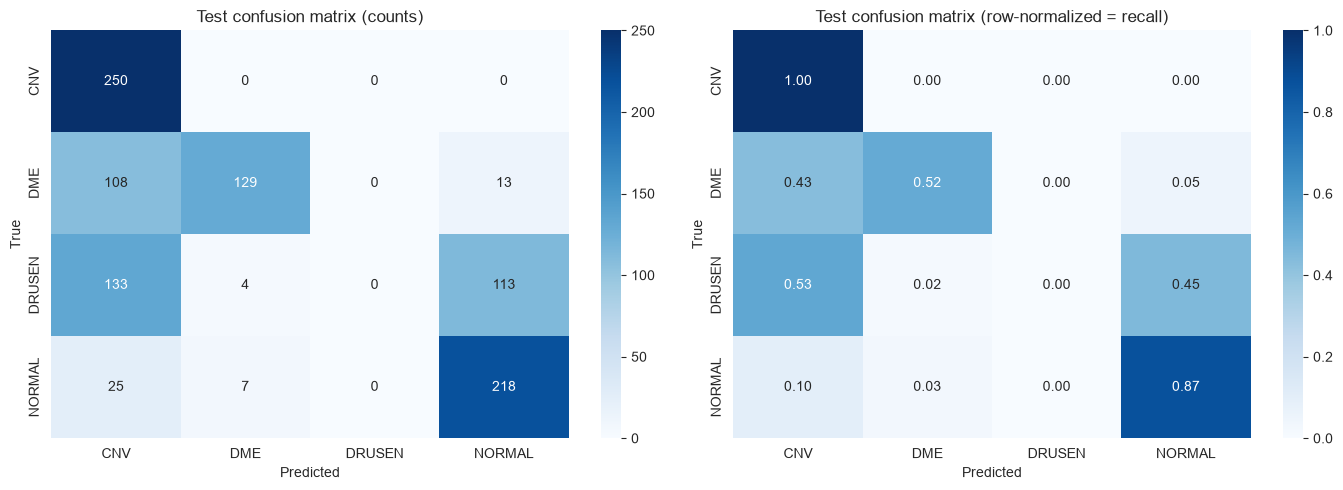

,class,recall,precision,F1,test scans
0,CNV,1.000,0.484,0.653,250
1,DME,0.516,0.921,0.662,250
2,DRUSEN,0.000,0.000,0.000,250
3,NORMAL,0.872,0.634,0.734,250


In [25]:
val_res = predict(final_model, val_loader)
test_res = predict(final_model, test_loader)
print(f"Validation: acc {val_res['acc']:.3f} | macro-F1 {val_res['f1']:.3f}")
print(f"Test:       acc {test_res['acc']:.3f} | macro-F1 {test_res['f1']:.3f} | CE loss {test_res['loss']:.3f}")
print("(chance level for 4 balanced classes = 0.25)")

cm = test_res["cm"]
recall = cm.diagonal() / cm.sum(1)
precision = cm.diagonal() / np.maximum(cm.sum(0), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Test confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True"); axes[1].set_title("Test confusion matrix (row-normalized = recall)")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"class": class_names, "recall": recall, "precision": precision, "F1": f1,
                      "test scans": cm.sum(1)}).round(3))

### Look at the mistakes

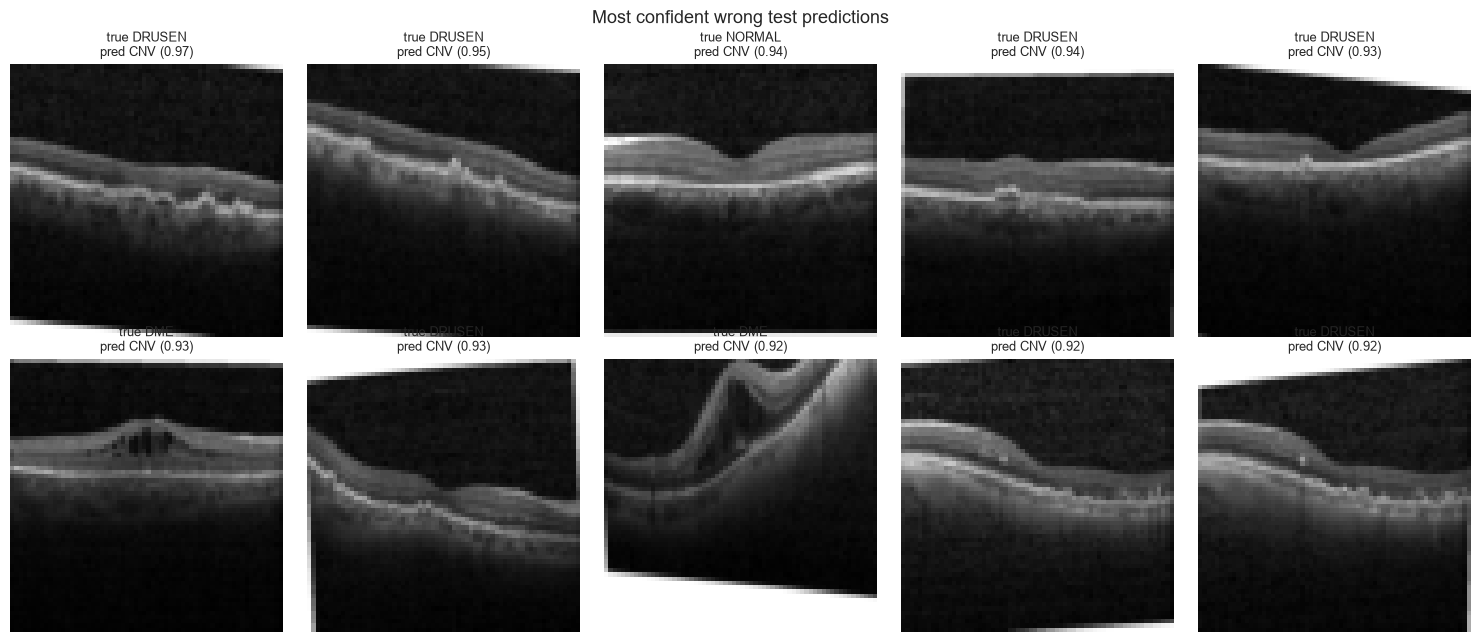

403 of 1000 test scans misclassified


In [26]:
wrong = np.where(test_res["pred"] != test_res["true"])[0]
conf = test_res["probs"].max(1)[wrong]
show = wrong[np.argsort(-conf)][:10]            # the most confident wrong predictions

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"true {class_names[test_res['true'][i]]}\npred {class_names[test_res['pred'][i]]} ({test_res['probs'][i].max():.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Most confident wrong test predictions", fontsize=13)
plt.tight_layout(); plt.show()
print(f"{len(wrong)} of {len(test_res['true'])} test scans misclassified")

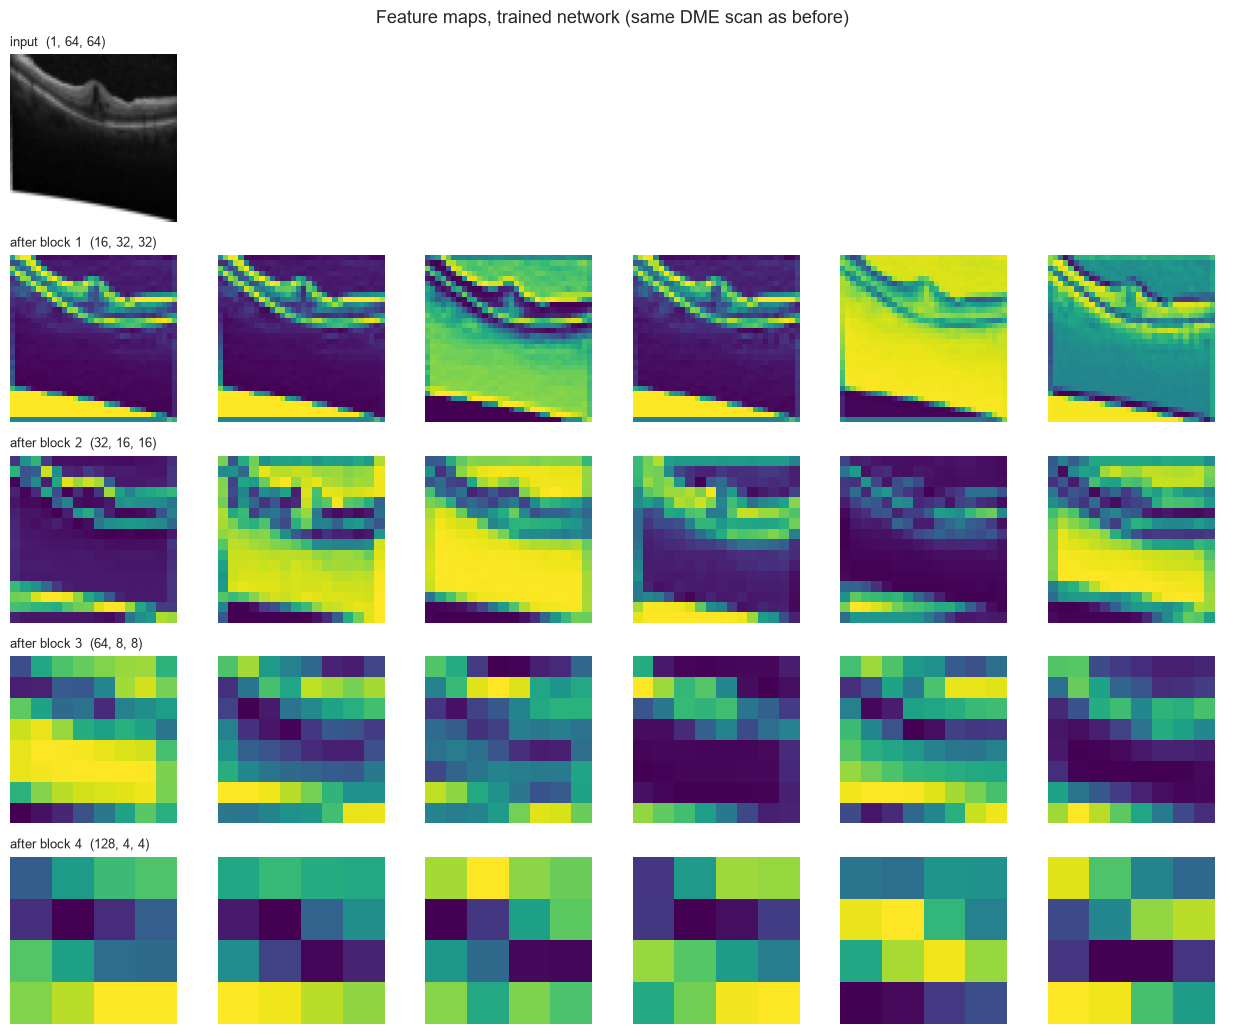

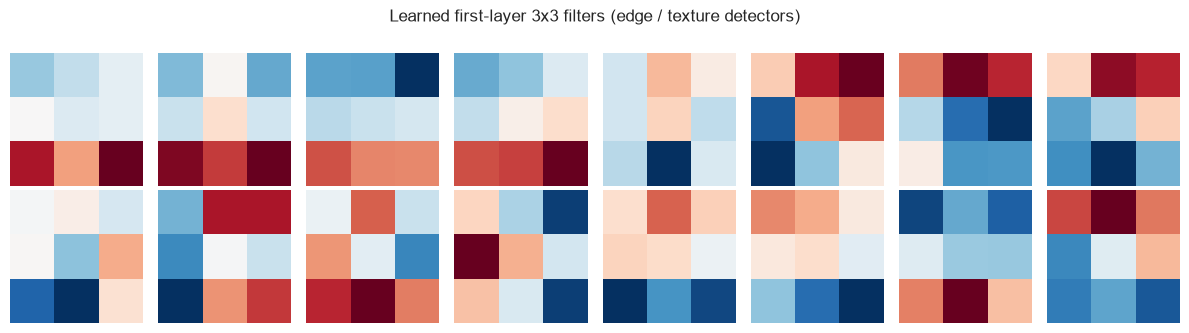

In [27]:
show_feature_maps(final_model, sample_img, "Feature maps, trained network (same DME scan as before)")

# first-layer filters (3x3 kernels learned from scratch)
w = final_model.features[0].weight.detach().cpu()        # (out, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, k in zip(axes.ravel(), w):
    lim = k.abs().max().item()
    ax.imshow(k[0], cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
plt.suptitle("Learned first-layer 3x3 filters (edge / texture detectors)")
plt.tight_layout(); plt.show()

### Save the model and settings for later steps

In [28]:
torch.save(final_model.state_dict(), "step4_custom_cnn.pt")
config4 = {
    "img_size": IMG_SIZE,
    "in_channels": 1,
    "architecture": {"channels": [16, 32, 64, 128], "act": FINAL["act"], "pool": FINAL["pool"], "fc_units": 128, "dropout": 0.4},
    "loss": FINAL["loss"], "batch_size": FINAL["bs"], "learning_rate": FINAL["lr"], "epochs_trained": len(final_hist["val_f1"]),
    "best_epoch": final_hist["best_epoch"],
    "pixel_mean": PIX_MEAN, "pixel_std": PIX_STD,
    "class_names": class_names, "class_weights": class_weights.tolist(),
    "val_accuracy": val_res["acc"], "val_macro_f1": val_res["f1"],
    "test_accuracy": test_res["acc"], "test_macro_f1": test_res["f1"],
    "seed": SEED,
}
with open("custom_cnn_config.json", "w") as f:
    json.dump(config4, f, indent=2)
print("Saved step4_custom_cnn.pt and custom_cnn_config.json")

Saved step4_custom_cnn.pt and custom_cnn_config.json


## Summary of Step 4
- Built a custom CNN in PyTorch: four Conv - BatchNorm - Activation - Pool blocks, global average pooling and a fully connected classifier with dropout.
- Wrapped the resized OCT scans in a custom `Dataset` with on-the-fly augmentation and normalization, and fed them through `DataLoader`s.
- Compared ReLU, LeakyReLU, GELU and Tanh; max vs average pooling; cross-entropy, class-weighted, label-smoothed and focal losses; batch sizes 16-128; learning rates 1e-4 to 1e-2.
- Trained a final model with a cosine schedule and early stopping on validation macro-F1, and judged it once on the untouched test split, reporting per-class recall, precision and F1.

**Cautions:** the experiments are short, single-seed screening runs on a small validation set (differences of a point or two are noise), and this Hugging Face copy has no patient IDs, so validation may share patients with training. The official test split is patient-independent, so trust it for the final number.

